# Bu projede, Trip Advisor otel yorumları zaman serisi analizi ile tarihsel olarak otel değerlendirme trendlerini incelemektedir.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv('tripadvisor_hotel_reviews.csv')

## EDA - Exploratory Data Analysis

In [4]:
df.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [5]:
df.shape

(20491, 2)

In [6]:
df.isnull().sum()

,0
Review,0
Rating,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20491 entries, 0 to 20490
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  20491 non-null  object
 1   Rating  20491 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 320.3+ KB


In [ ]:
# Yıldızların türüne göre toplamı ve yüzdesi

In [10]:
stars=df.groupby('Rating').size().reset_index(name='count')
stars['percentage']=(stars['count'] / stars['count'].sum())*100
stars

,Rating,count,percentage
0,1,1421,6.934752
1,2,1793,8.750183
2,3,2184,10.658338
3,4,6039,29.471475
4,5,9054,44.185252


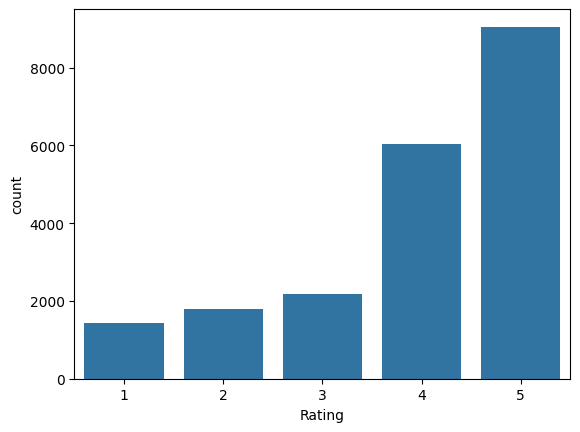

In [11]:
sns.countplot(x=df["Rating"]);

## Adding Sentiment Features

In [12]:
df.loc[(df['Rating'] == 1) | (df['Rating'] == 2), 'sentiment'] = 'negative'
df.loc[df['Rating'] == 3, 'sentiment'] = 'neutral'
df.loc[(df['Rating'] == 4) | (df['Rating'] == 5), 'sentiment'] = 'positive'

In [13]:
df.columns

Index(['Review', 'Rating', 'sentiment'], dtype='object')

In [16]:
df['Review'] = df['Review'].str.lower()
df['Review'] = df['Review'].replace('[^\w\s]', '', regex=True)
df['Review'] = df['Review'].replace('\n', '', regex=True)
df['Review'] = df['Review'].replace('\d+', '', regex=True)
df['Review'] = df['Review'].replace('\r', '', regex=True)

In [17]:
# Yeni bir sütun ekleyerek dilleri tespit etme (ChatGPT den yardım alındı.)

In [19]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 5.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993221 sha256=91b6dae8d86771e624038859265a0f4ec11906b4e0f5f7a67d1478846b37ac13
  Stored in directory: /root/.cache/pip/wheels/95/03/7d/59ea870c70ce4e5a370638b5462a7711ab78fba2f655d05106
Successfully built langdetect


In [21]:
from langdetect import detect, DetectorFactory
def detect_language(Review):
    try:
        return detect(Review)
    except:
        return None  # Hata olursa None döndür
df['language'] = df['Review'].apply(detect_language)

In [22]:
df['language'].value_counts()

,count
language,
en,20473
fr,7
af,3
es,2
ca,2
ro,2
nl,1
it,1


In [23]:
# Sadece İngilizce olanları alıyoruz.

In [25]:
df['language']=df['Review'].apply(detect)
df=df[df['language']=='en']

In [26]:
from wordcloud import WordCloud
from wordcloud import STOPWORDS
from PIL import Image #klasörün içerisindeki resimleri okumak için
import numpy as np

In [27]:
def wc(data,bgcolor):
    plt.figure(figsize=(10,10))
    mask=np.array(Image.open('cloud.png'))
    wc=WordCloud(background_color=bgcolor,stopwords=STOPWORDS,mask=mask)
    wc.generate(''.join(data))  # generate --> wordcloud u oluşturmak demek. Bütün sutunlardaki kelimeri alıp birleştirecek ve onların içinden en çok geçen kelimeleri bulup sayacak ve wc'yi oluşturacak
    plt.imshow(wc) #Oluşturduğu resmi göstermesini isteyeceğiz.
    plt.axis('off') # x ve y eksenlerini göstermemesi için.

In [28]:
df.columns

Index(['Review', 'Rating', 'sentiment', 'language'], dtype='object')

In [29]:
d={'neutral':0,'negative':1,'positive':2}
df['sentiment']=df['sentiment'].map(d)

<ipython-input-29-20e09744c01e>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sentiment']=df['sentiment'].map(d)


In [30]:
neutral=df[df['sentiment']==0]['Review']
negative=df[df['sentiment']==1]['Review']
positive=df[df['sentiment']==2]['Review']

In [31]:
df.head()

,Review,Rating,sentiment,language
0,nice hotel expensive parking got good deal sta...,4,2,en
1,ok nothing special charge diamond member hilto...,2,1,en
2,nice rooms not experience hotel monaco seattl...,3,0,en
3,unique great stay wonderful time hotel monaco ...,5,2,en
4,great stay great stay went seahawk game awesom...,5,2,en


In [32]:
df[df['sentiment'] == 1]

,Review,Rating,sentiment,language
1,ok nothing special charge diamond member hilto...,2,1,en
10,poor value stayed monaco seattle july nice hot...,2,1,en
15,horrible customer service hotel stay february ...,1,1,en
16,disappointed say anticipating stay hotel monac...,2,1,en
24,great location need internally upgrade advanta...,2,1,en
...,...,...,...,...
20484,deceptive staff deceptive desk staff claiming ...,2,1,en
20485,not impressed unfriendly staff checked asked h...,2,1,en
20488,ok just looks nice modern outside desk staff n...,2,1,en
20489,hotel theft ruined vacation hotel opened sept ...,1,1,en


In [34]:
five_stars=df[df['Rating'] == 5]['Review']

In [35]:
one_stars=df[df['Rating'] == 1]['Review']

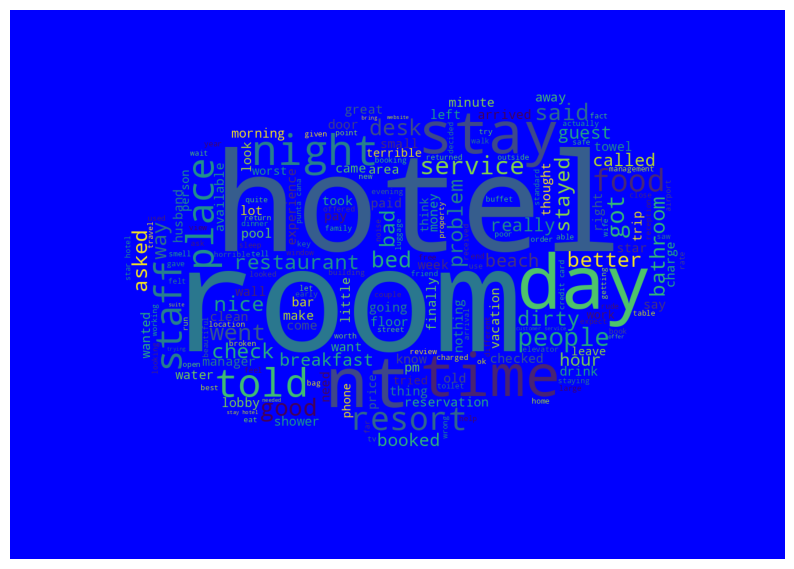

In [37]:
wc(one_stars,'blue')

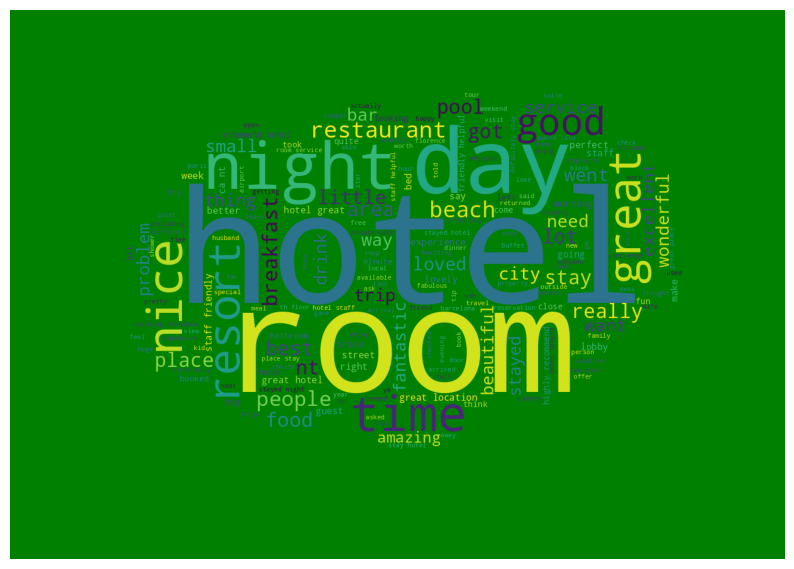

In [38]:
wc(five_stars,'green')

In [40]:
df['Rating'].unique()

array([4, 2, 3, 5, 1])

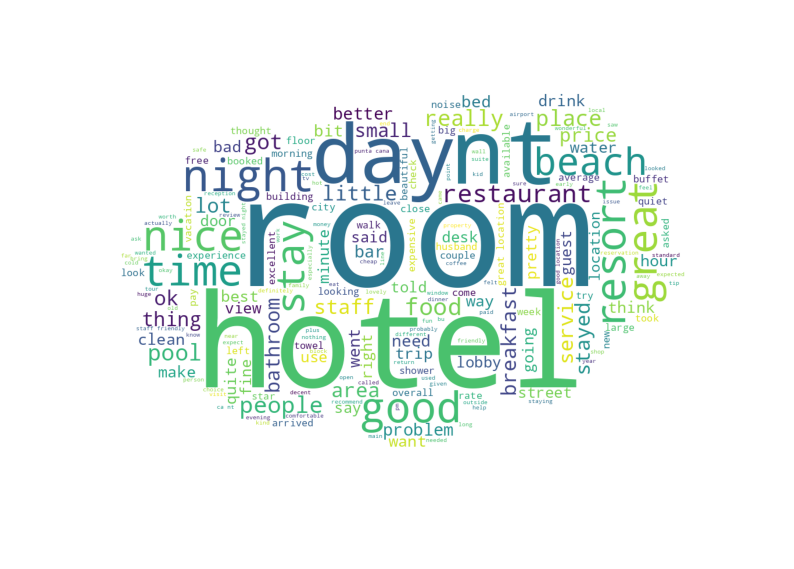

In [41]:
wc(neutral,'white')

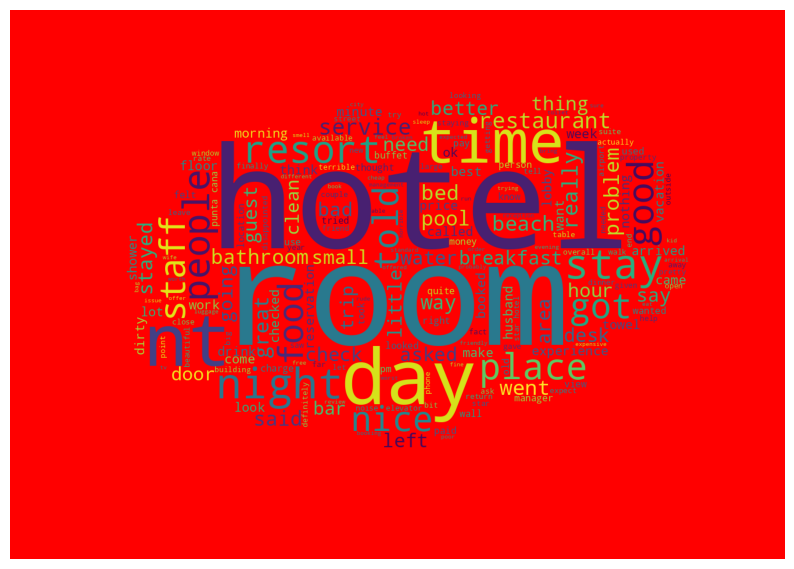

In [42]:
wc(negative,'red')

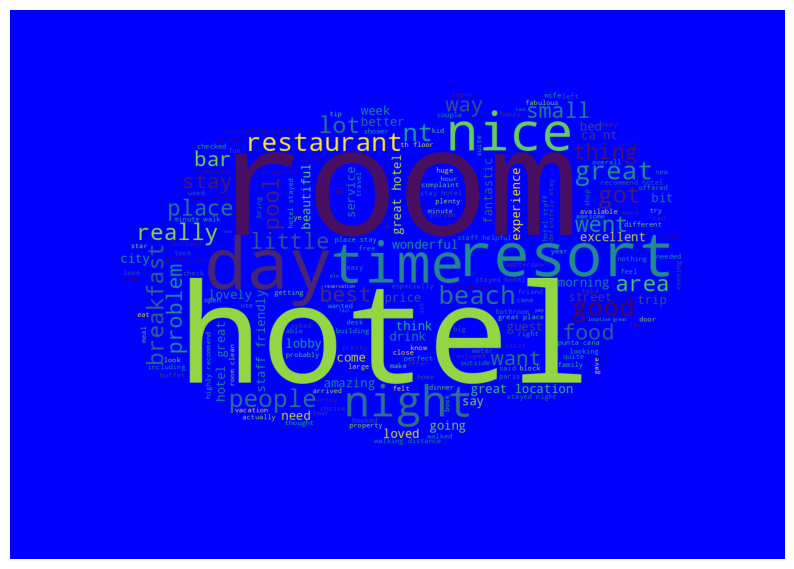

In [43]:
wc(positive,'blue')

In [44]:
x=df["Review"]
y=df['sentiment']

In [45]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

In [48]:
from textblob import TextBlob
from nltk.stem import PorterStemmer
pr=PorterStemmer()

In [49]:
def lemmafn(Review): #Kelimelerin eklerini kaldırıp köklerini bulan fonksiyon
    words=TextBlob(Review).words
    return [pr.stem(word) for word in words]

In [50]:
vect=CountVectorizer(stop_words='english', ngram_range=(1,2),analyzer=lemmafn)

In [52]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [53]:
x=vect.fit_transform(x)

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
x_train, x_test, y_train, y_test=train_test_split(x,y,random_state=42, test_size=0.20)

In [56]:
nb=MultinomialNB()

In [57]:
model=nb.fit(x_train,y_train)

In [58]:
tahmin=model.predict(x_test)

In [59]:
accuracy_score(tahmin,y_test)

0.8417582417582418

In [60]:
tahmin

array([2, 2, 1, ..., 2, 2, 2])

In [61]:
from sklearn.linear_model import LogisticRegression

In [62]:
lr=LogisticRegression()

In [63]:
model=lr.fit(x_train,y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [64]:
lr_tahmin=lr.predict(x_test)

In [65]:
accuracy_score(lr_tahmin,y_test)

0.8463980463980464

In [66]:
from sklearn.naive_bayes import BernoulliNB

In [67]:
b=BernoulliNB()

In [68]:
model=b.fit(x_train,y_train)

In [69]:
tahmin=b.predict(x_test)

In [70]:
accuracy_score(tahmin,y_test)

0.7499389499389499

In [71]:
from sklearn.ensemble import RandomForestClassifier

In [72]:
r=RandomForestClassifier()

In [73]:
model=r.fit(x_train,y_train)

In [74]:
tahmin=r.predict(x_test)

In [75]:
accuracy_score(tahmin,y_test)

0.77997557997558

In [76]:
from sklearn.tree import DecisionTreeClassifier

In [77]:
d=DecisionTreeClassifier()

In [78]:
model=d.fit(x_train,y_train)

In [79]:
tahmin=d.predict(x_test)

In [80]:
accuracy_score(tahmin,y_test)

0.747985347985348

In [81]:
confusion_matrix(lr_tahmin,y_test)

array([[ 136,   91,  137],
       [ 118,  518,   47],
       [ 167,   69, 2812]])